# Keep the LLM's Answer When It Fails Validation

In this video, I'm going to keep an LLM's whole answer about a photo when it fails a Pydantic model. The error stays on its row, and we'll rerun the LLM only for the photos that failed.

With Pydantic alone, one bad field raises an error for the whole model, and the fields that passed don't come back either. Two threads in the Pydantic repo ask about this: how to keep the valid fields, and how to fall back instead of crashing.

*Show pydantic issue #9371 and discussion #13811.*

We'll see that failure in plain Pydantic first, then put the same answer in a Pixeltable table. The notebook is in the `keep-failed-answers` folder of the repo linked below.

## Start from an empty `answers_demo` directory

Start Jupyter with `uv run jupyter lab` in this folder. When we sent these six photos to Gemini, every answer fit our Pydantic model, so the LLM calls here go to a stand-in that breaks two of those answers. It needs no API key.

In [1]:
!uv sync

Resolved 159 packages in 3ms
Audited 149 packages in 2ms


In [2]:
import pixeltable as pxt
from pydantic import ValidationError

import stand_in
from schema import ListingDetails

# Start fresh: drop the tables from any earlier run.
pxt.drop_dir('answers_demo', force=True, if_not_exists='ignore')

Creating a Pixeltable instance at: <scratchpad>/kfa-nb5/.pxt-home


Connected to Pixeltable database at: postgresql+psycopg://postgres:***@/pixeltable?host=%2Fvar%2Ffolders%2Fzz%2Fd4wytf2s44996j3sr4zgthw80000gn%2FT%2F91e13a7abb


## One wrong field fails the whole Pydantic model

Here's the Pydantic model the LLM's answer has to fit. All six fields are required, and `category` and `condition` allow only a few values.

In [3]:
!sed -n '14,22p' schema.py

class ListingDetails(BaseModel):
    """What the LLM writes from a seller's photo."""

    title: str = Field(description='A listing title, under 60 characters')
    category: Literal['cameras', 'bikes', 'home', 'bags', 'instruments', 'other']
    condition: Literal['new', 'like new', 'good', 'fair']
    color: str
    description: str = Field(description='Two or three sentences for buyers, about only what the photos show')
    pitch: str = Field(description='Narration for a 10-second listing video: two short spoken sentences, 15 to 25 words')


This is Gemini's answer for a photo of a film camera, from our run, with one change: `color` is a list instead of a string.

In [4]:
answer = dict(stand_in.ANSWERS['film-camera-1']['answer'], color=['Silver', 'Black'])  # a list, not a string
answer

{'title': 'Vintage Style SLR Film Camera in Silver and Black',
 'category': 'cameras',
 'condition': 'good',
 'color': ['Silver', 'Black'],
 'description': 'This manual SLR camera features a silver chrome top and base paired with a black textured body wrap. It is fitted with a central lens showing clear glass, along with top-mounted control dials and a prism viewfinder. The exterior is well-maintained with clean edges and minimal surface wear visible.',
 'pitch': 'Take a look at this classic silver and black SLR camera. It features a clean body with all original dials intact.'}

`model_validate` returns a `ListingDetails`, or raises a `ValidationError`.

In [5]:
details = None
try:
    details = ListingDetails.model_validate(answer)
except ValidationError as e:
    print(e)
print(details)

1 validation error for ListingDetails
color
  Input should be a valid string [type=string_type, input_value=['Silver', 'Black'], input_type=list]
    For further information visit https://errors.pydantic.dev/2.14/v/string_type
None


It raised for `color`, and `details` is still `None`. The other five fields were fine, and none of them came back.

*Show the maintainer's reply in discussion #13811.*

Pydantic's maintainers suggest wrapping each field in a validator that falls back to a default. That works, but you have to wrap every field and give each one a default.

## The answer and its check go in two columns

Pixeltable is a multimodal backend, and you declare its tables in Python. In `listings`, the only columns you fill in are `name` and `photo`. `response` and `details` are computed columns, so Pixeltable computes them for every row you insert.

In [6]:
!sed -n '10,12p;25,40p' schema.py

MODEL = 'gemini-3.8-flash'
DETAILS_PROMPT = 'Write a marketplace listing for the item in these photos. Describe only what the photos show.'

def json_config(model: type[BaseModel]) -> dict:
    """Gemini config that asks for JSON in the shape of `model`."""
    return {'response_mime_type': 'application/json', 'response_json_schema': model.model_json_schema()}


TableModel = pxt.model_base()


class Listings(TableModel, name='listings'):
    name: pxt.String
    photo: pxt.Image

    # The LLM's whole answer, as it came back. The stand-in is demo only.
    response = stand_in_gemini([DETAILS_PROMPT, photo], model=MODEL, config=json_config(ListingDetails))
    # The answer checked against ListingDetails. A missing field or a wrong type is an error on this row.
    details = response.parsed.astype(pxt.Json[ListingDetails])


`response` calls the LLM with the prompt and the photo, and asks for JSON in the shape of `ListingDetails`. It keeps the whole answer as it came back.

`details` takes the answer's `parsed` field, the JSON the LLM returned, and checks it against `ListingDetails`: every field there, with the right type. It doesn't run your validators or check `Literal` values, so a `condition` of "barely used" would pass.

`stand_in_gemini` is the demo-only part, with the same arguments as `pxtf.gemini.generate_content`.

In [7]:
!sed -n '25,41p' stand_in.py

BROKEN = ['film-camera-1', 'guitar-1']  # the stand-in breaks the answers for these photos
CALLS: list[str] = []  # every photo the stand-in was called for, in order


@pxt.udf
def stand_in_gemini(contents: pxt.Json, *, model: str, config: dict | None = None) -> dict:
    """Takes the same arguments as pxtf.gemini.generate_content, and returns Gemini's answer as `parsed`."""
    prompt, photo = contents
    name = photo_name(photo)
    CALLS.append(name)
    answer = dict(ANSWERS[name]['answer'])
    if name in BROKEN:
        if name == 'film-camera-1':
            answer['color'] = ['Silver', 'Black']  # a list, not a string
        if name == 'guitar-1':
            del answer['condition']  # a required field, left out
    return {'parsed': answer}


It returns each answer under `parsed`, where Gemini's response puts its JSON. `BROKEN` names the two photos whose answers it breaks, and `CALLS` records every photo it's called for.

`pxt schema diff` shows the plan, and `pxt schema update` creates the table.

In [8]:
!pxt schema diff schema.py answers_demo

+ answers_demo/listings    create

Plan: 1 create, 0 update, 0 unchanged, 0 extra  |  0 destructive


In [9]:
!pxt schema update schema.py answers_demo -f

created   answers_demo/listings


## By default, one failed check stores none of the rows

I'll insert six photos of secondhand items. Each `photo` is a URL, and Pixeltable downloads the photo when it inserts the row.

In [10]:
BASE = 'https://raw.githubusercontent.com/apreshill/pixeltable-marketplace/main/samples/'
NAMES = ['desk-lamp-1', 'film-camera-1', 'guitar-1', 'backpack-1', 'cruiser-bike-1', 'salt-lamp-1']
rows = [{'name': name, 'photo': f'{BASE}{name}.jpg'} for name in NAMES]

listings = pxt.get_table('answers_demo.listings')
try:
    listings.insert(rows)
except pxt.Error as e:
    print(str(e).splitlines()[1])  # the error, without the long expression around it
listings.count()

Expected string, got list


0

The film camera's answer failed the check, so the insert stored none of the six rows. With a real LLM, you'd pay for those calls and keep none of the answers.

## With `on_error='ignore'`, every row is stored with its error

`on_error='ignore'` stores every row, and keeps each error on the row it came from.

In [11]:
listings.insert(rows, on_error='ignore')

Inserted 6 rows with 2 errors across 1 column (listings.details) in 0.04 s (139.55 rows/s)


6 rows inserted, 2 exceptions.

Six rows, with two errors, both in `details`. Every computed column has an `errortype` and an `errormsg` you can select.

photo,name,details_errortype,details_errormsg
,film-camera-1,TypeError,"Expected string, got list"
,guitar-1,TypeError,Missing required key: 'condition'
,desk-lamp-1,NaN,NaN
,backpack-1,NaN,NaN
,cruiser-bike-1,NaN,NaN
,salt-lamp-1,NaN,NaN

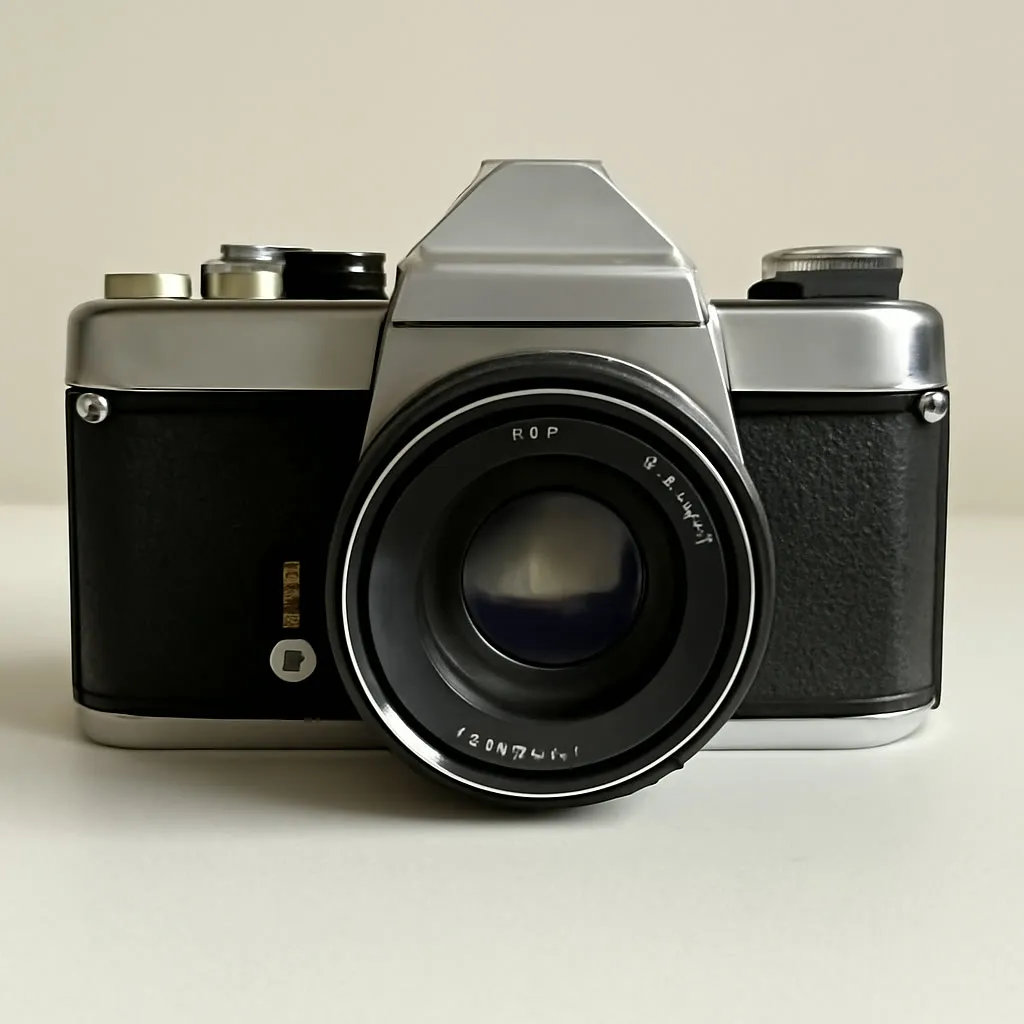
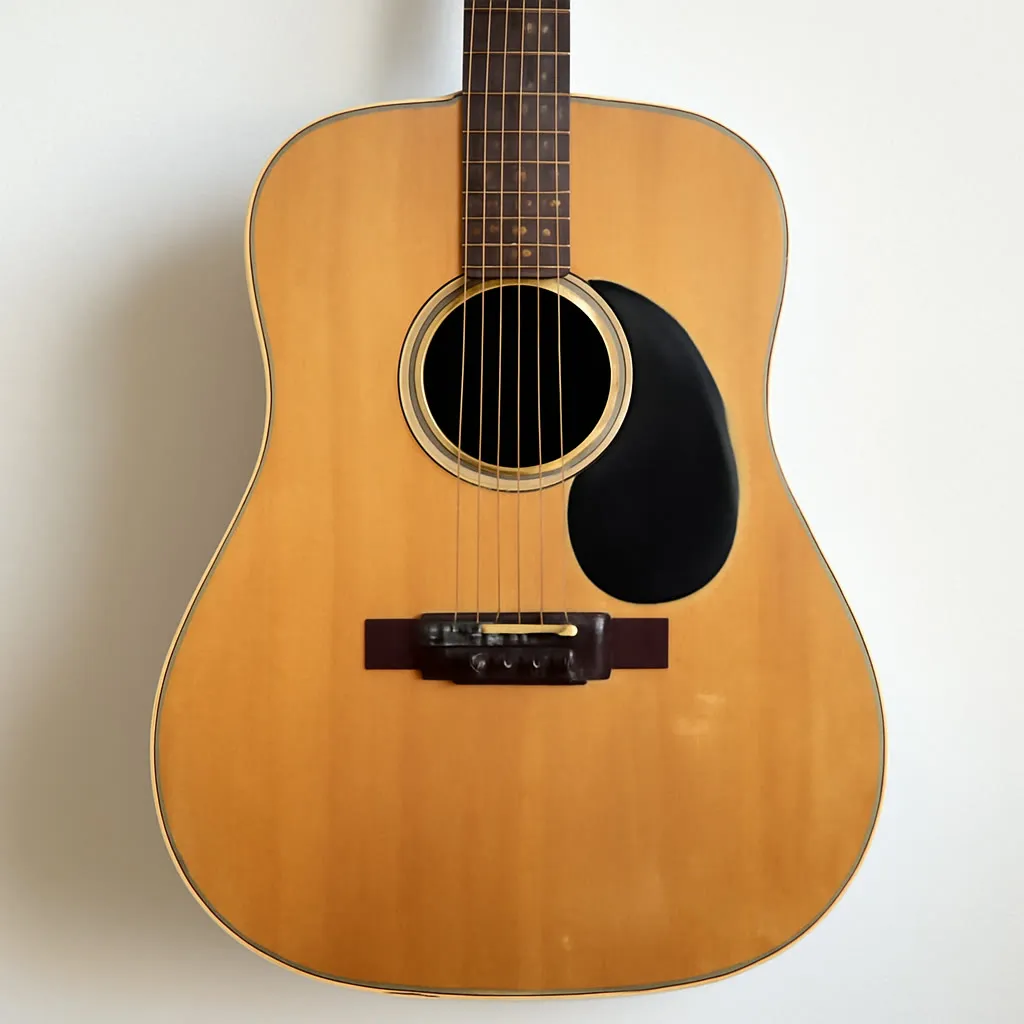
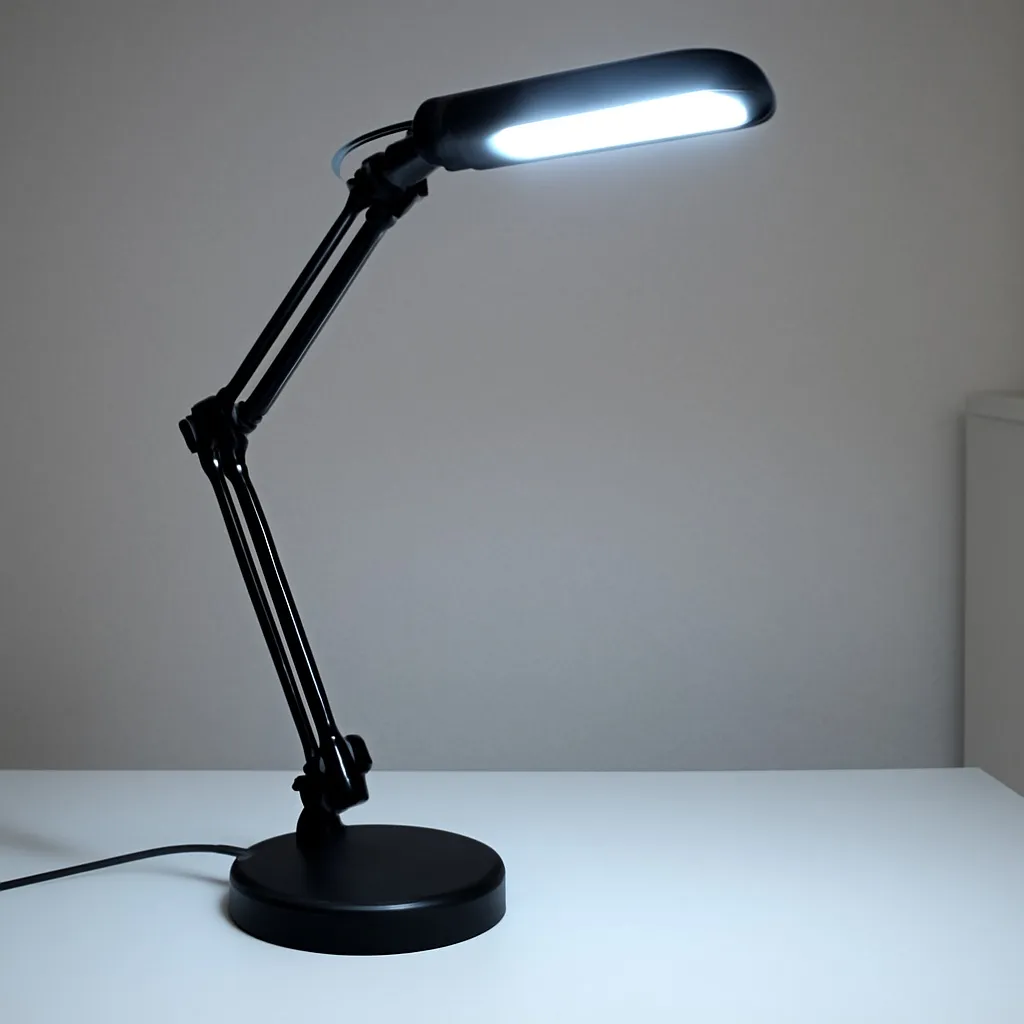
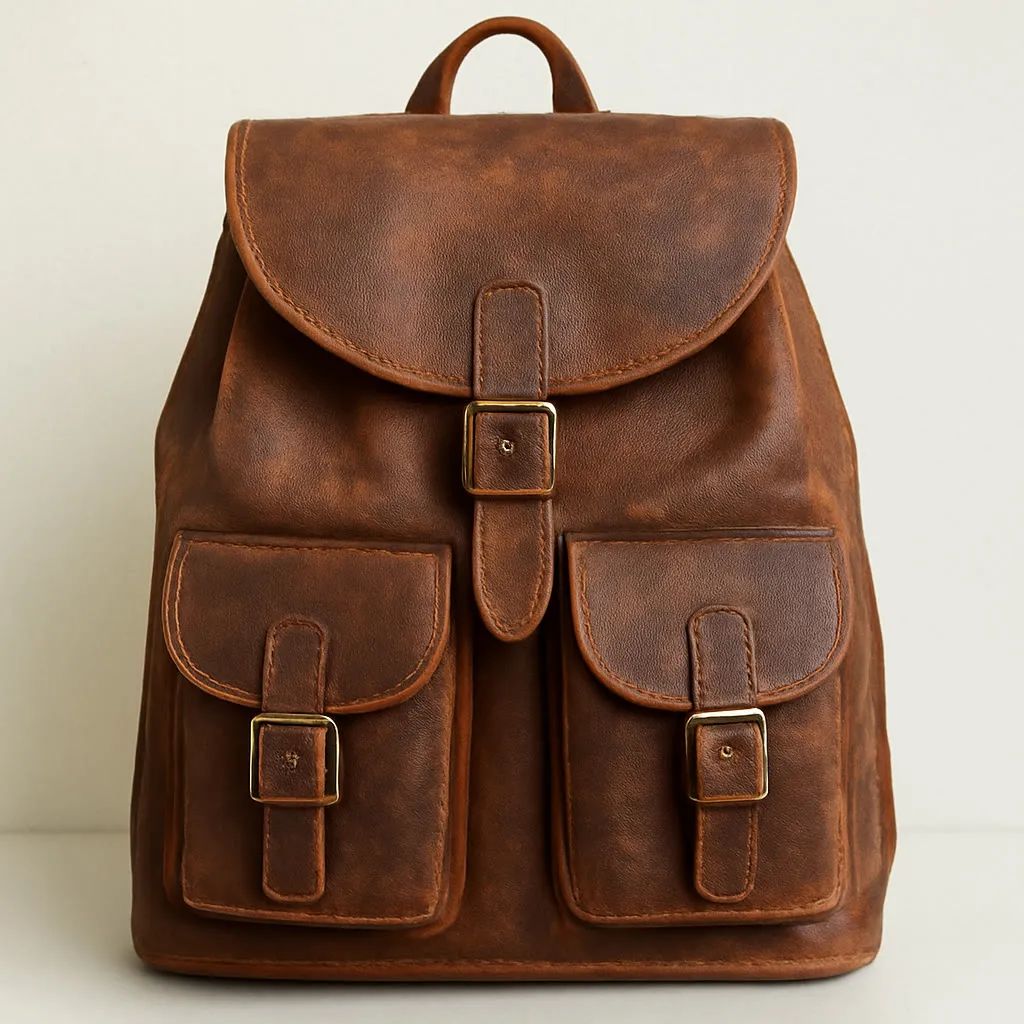
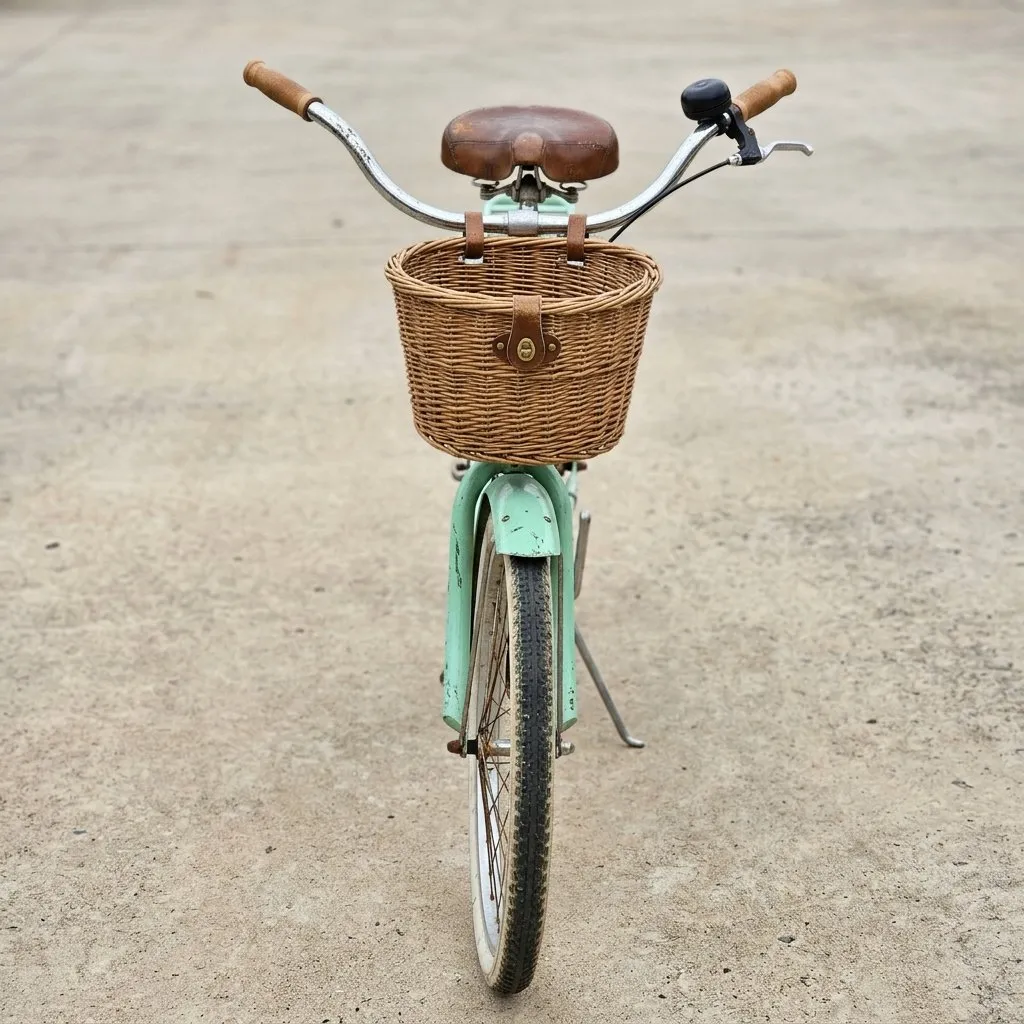
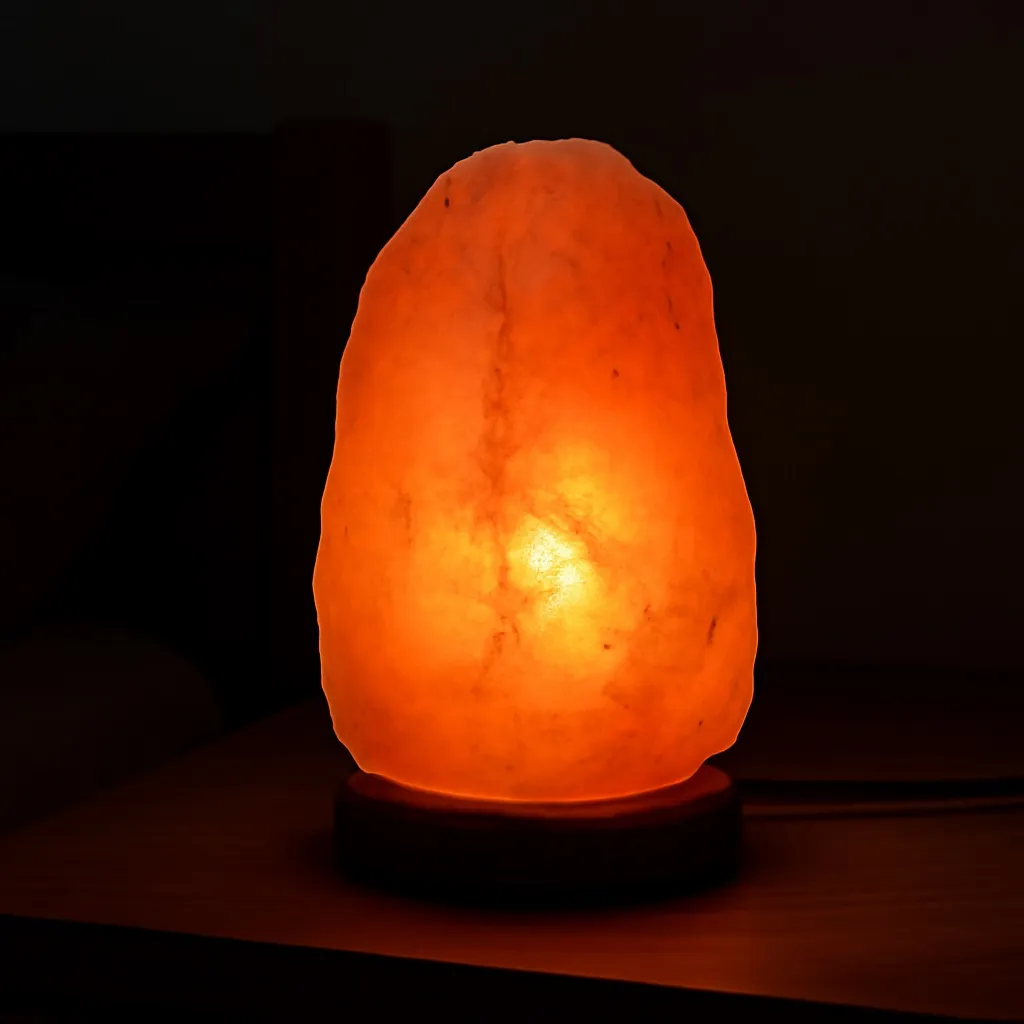

In [12]:
listings.select(listings.photo, listings.name, listings.details.errortype, listings.details.errormsg).collect()

The film camera's `color` is a list, and the guitar's answer left out `condition`. The other four answers passed the check.

`failed` is every row where `details` has an error. Here's what those two rows kept.

In [13]:
failed = listings.details.errortype != None
listings.where(failed).select(
    listings.name,
    listings.response.parsed.title,
    listings.response.parsed.condition,
    listings.response.parsed.color,
    listings.details,
).collect()

name,response_parsed_title,response_parsed_condition,response_parsed_color,details
film-camera-1,Vintage Style SLR Film Camera in Silver and Black,good,"[""Silver"", ""Black""]",None
guitar-1,6-String Acoustic Guitar with Natural Finish,NaN,Natural,None


`response` still has each whole answer, title included. `details` is empty on these rows, because this works per row, not per field. Pixeltable doesn't keep a partial `ListingDetails`.

## Rerun the LLM call, not the check, on the rows that failed

The errors are in `details`, so the first thing to try is `errors_only=True` on `details`.

In [14]:
stand_in.CALLS.clear()
listings.recompute_columns(listings.details, errors_only=True).num_rows

2

In [15]:
stand_in.CALLS, listings.where(failed).count()

([], 2)

It checked the same two answers again, and both still fail. The stand-in wasn't called at all.

To get new answers, we rerun `response`. `errors_only=True` won't find these rows there, because the LLM call itself worked, so a `where` on `details.errortype` picks them.

With a real LLM, a rerun is a new call, so the answer can come back whole or fail the same way again. The stand-in always breaks the same two answers, so I'll clear its `BROKEN` list first.

In [16]:
stand_in.BROKEN.clear()  # demo only: the stand-in stops breaking answers
listings.recompute_columns(listings.response, where=failed).num_rows

2

In [17]:
stand_in.CALLS

['film-camera-1', 'guitar-1']

The stand-in was called for the film camera and the guitar, and no other photo. Pixeltable reran `details` after `response`, because `details` is built on it.

photo,name,details_condition,details_color,details_errortype
,desk-lamp-1,like new,black,None
,backpack-1,like new,Brown,None
,cruiser-bike-1,fair,Mint green,None
,salt-lamp-1,good,Orange,None
,film-camera-1,good,Silver,None
,guitar-1,good,Natural,None

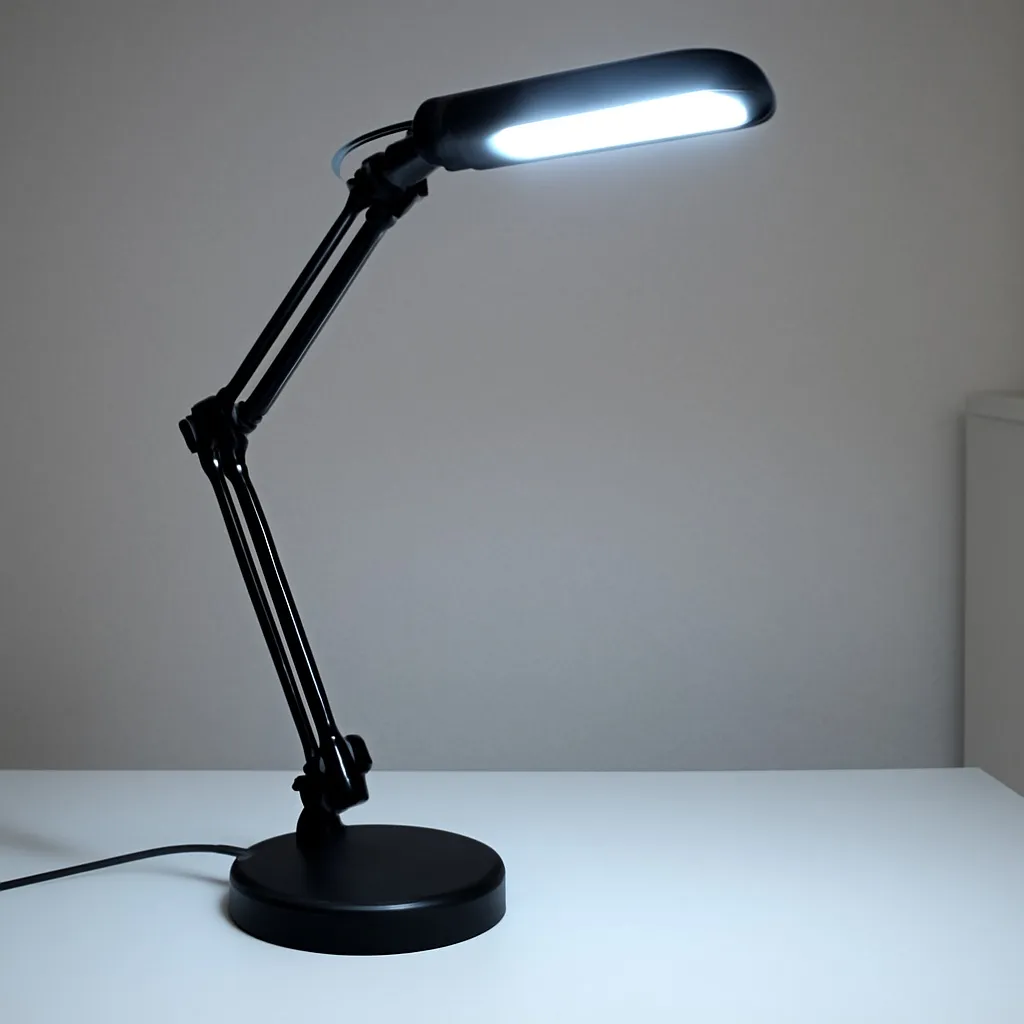
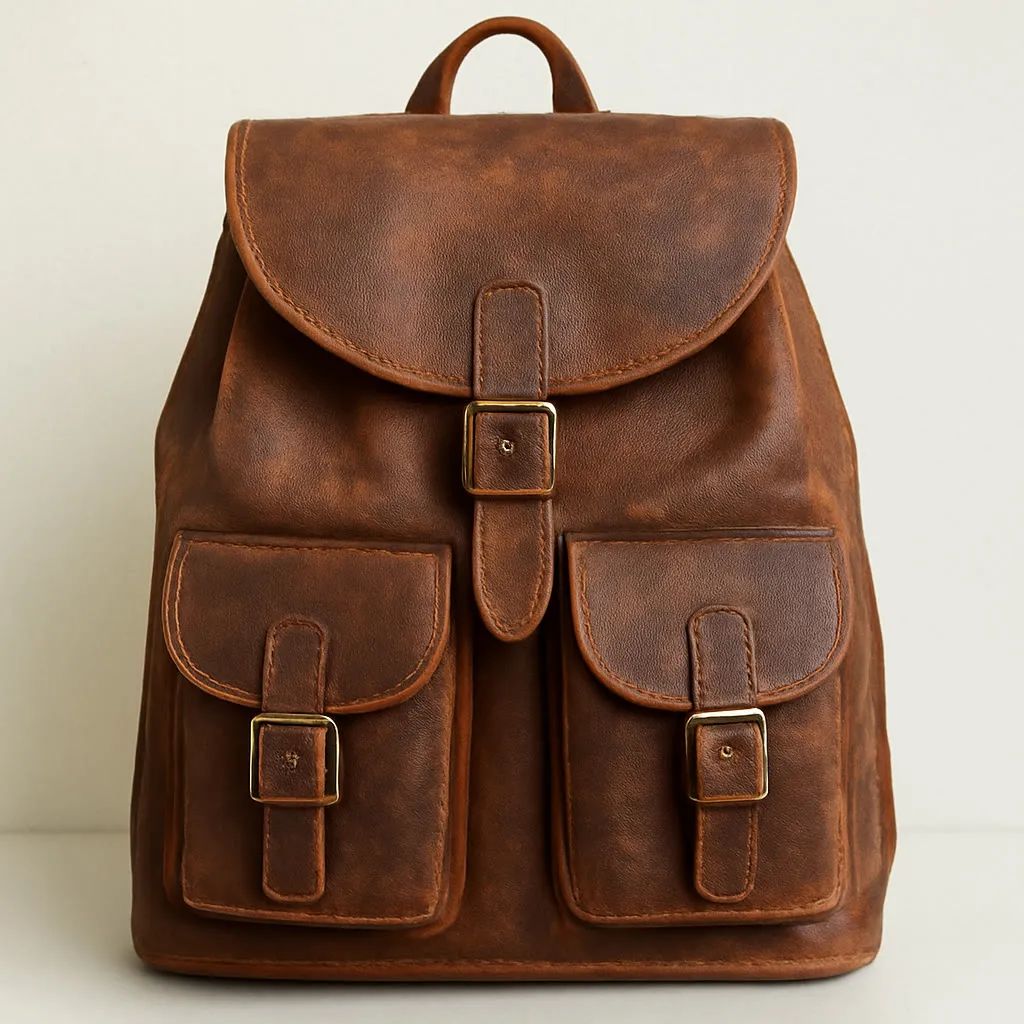
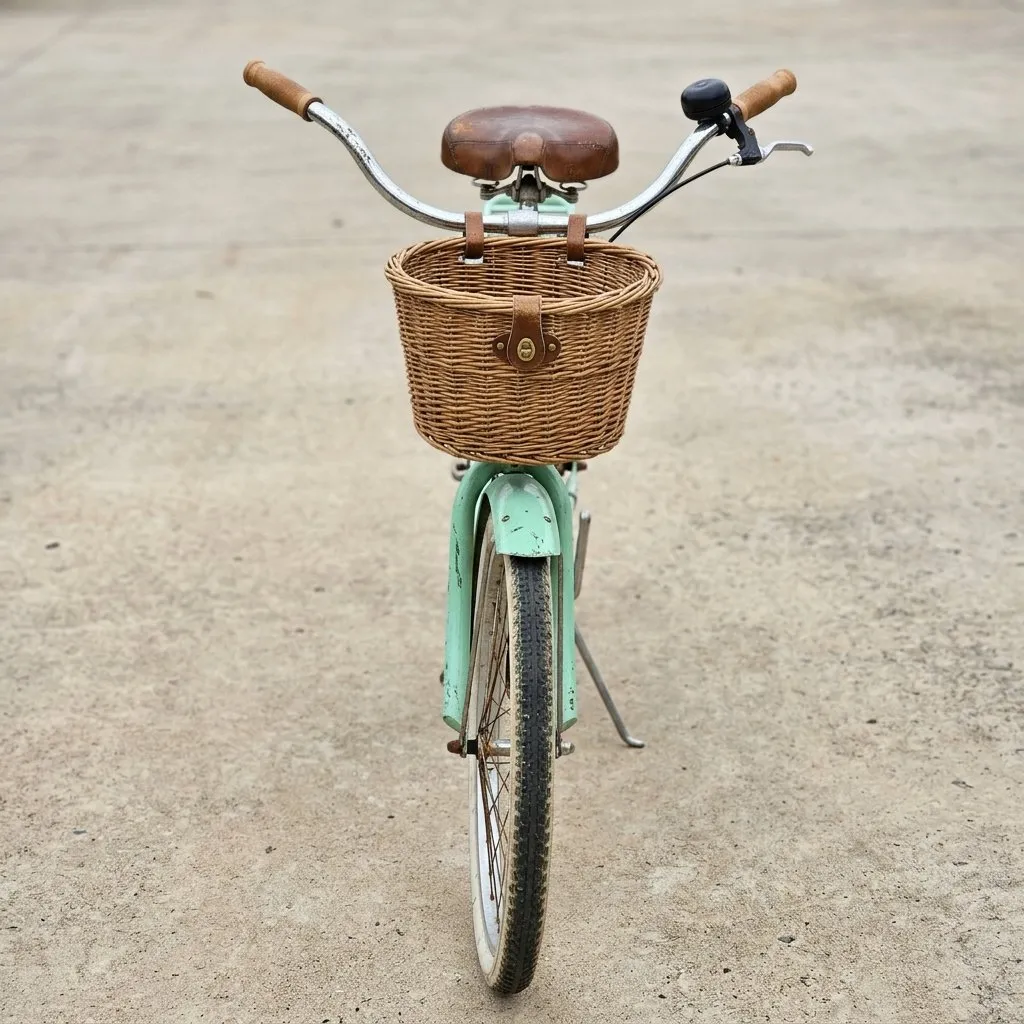
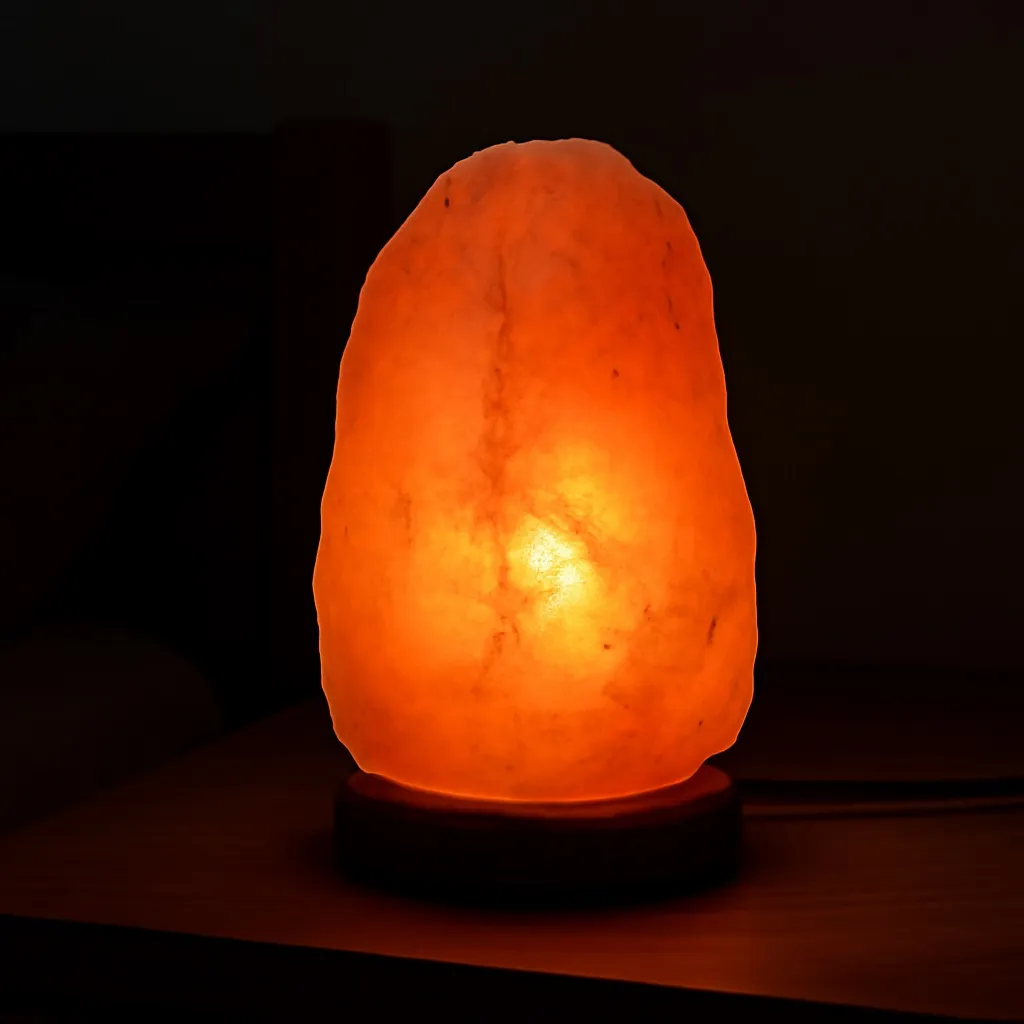
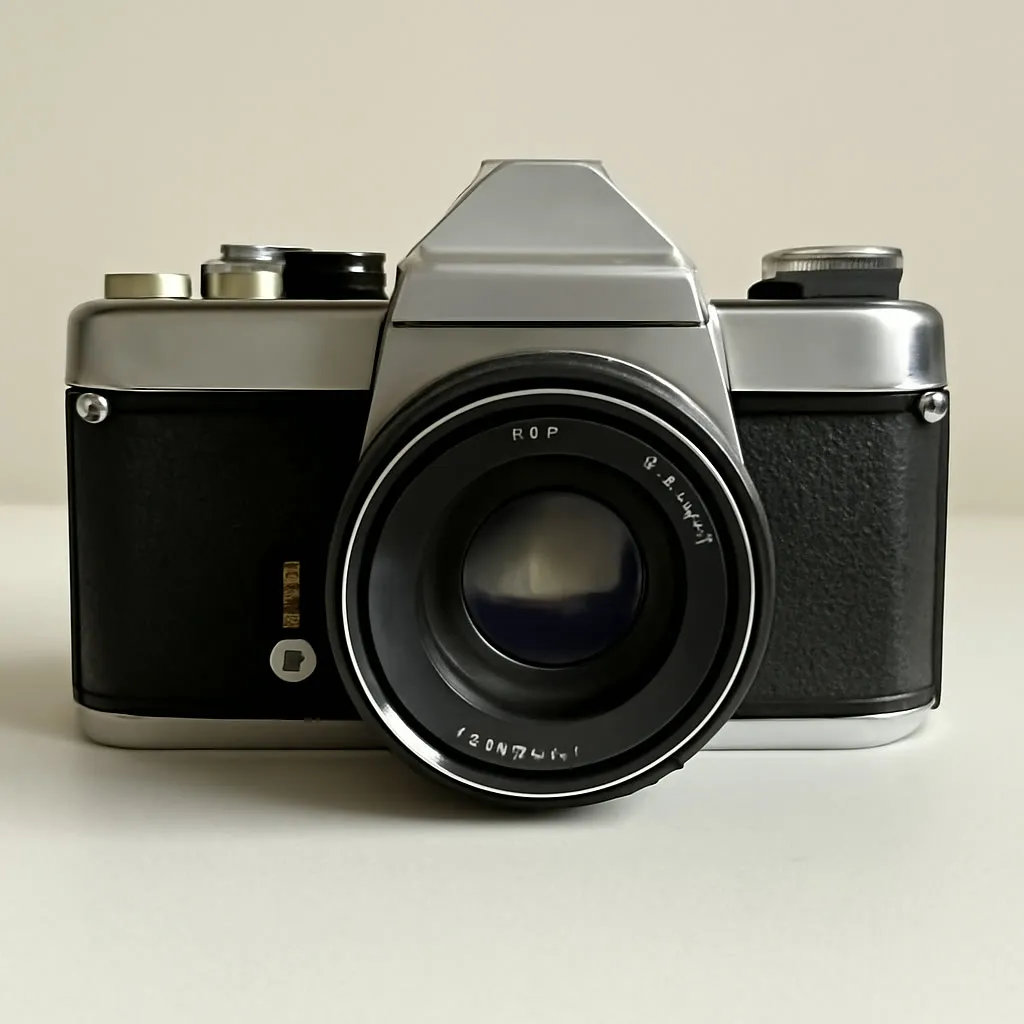
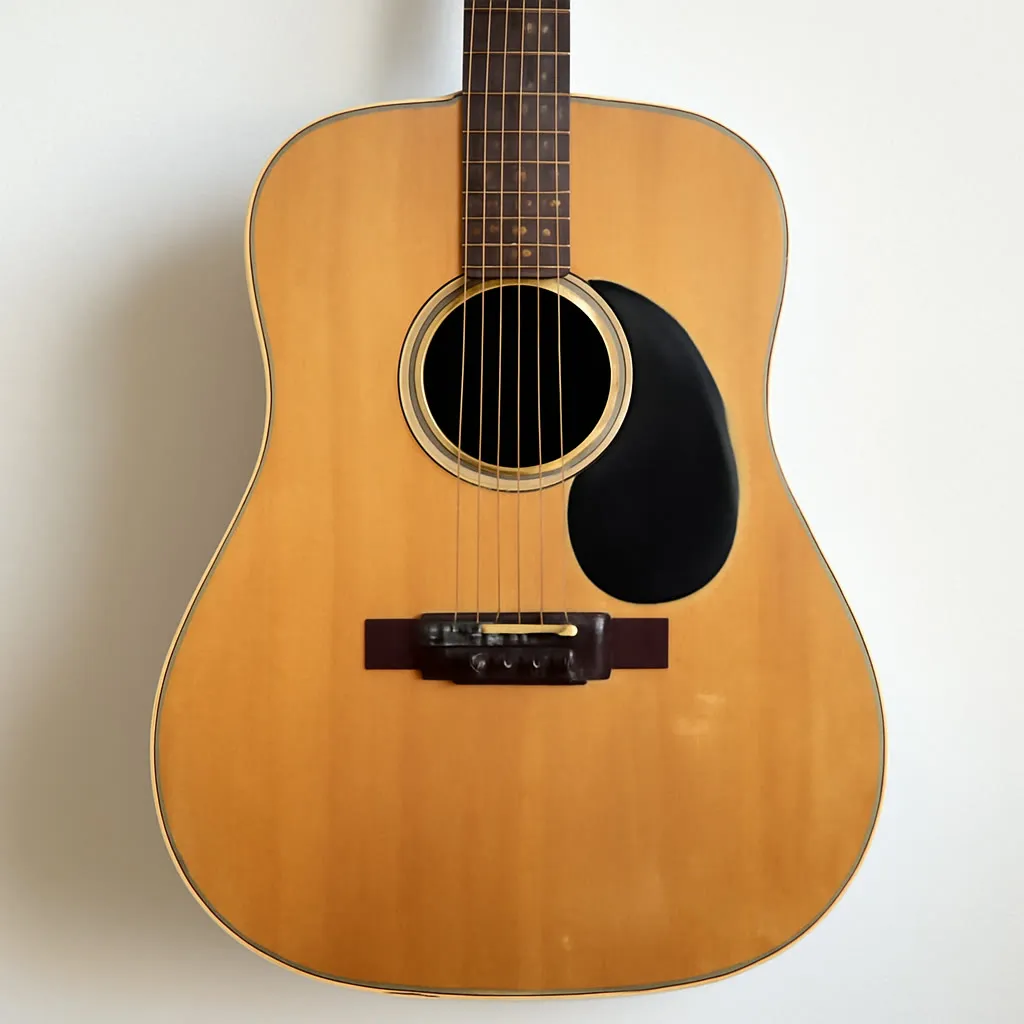

In [18]:
listings.select(listings.photo, listings.name, listings.details.condition, listings.details.color, listings.details.errortype).collect()

Every row passes the check now, and the stand-in was never called again for the four answers that passed the first time.

## For real Gemini calls, `schema_gemini.py` changes the `response` line

This file is the same table, with `pxtf.gemini.generate_content` in place of the stand-in.

In [19]:
!diff schema.py schema_gemini.py

5a6
> import pixeltable.functions as pxtf
8,9d8
< from stand_in import stand_in_gemini
< 
37,38c36,37
<     # The LLM's whole answer, as it came back. The stand-in is demo only.
<     response = stand_in_gemini([DETAILS_PROMPT, photo], model=MODEL, config=json_config(ListingDetails))
---
>     # The LLM's whole answer, as it came back.
>     response = pxtf.gemini.generate_content([DETAILS_PROMPT, photo], model=MODEL, config=json_config(ListingDetails))


Set `GEMINI_API_KEY` before you use it.

## Each failed answer stayed on its row

We kept the LLM's whole answer in one column and its check against the Pydantic model in another. With `on_error='ignore'`, the two answers that failed stayed on their rows with their errors, and the rerun called the LLM only for those two.

For big batches, our video Rerun Only the Failures, linked in the description, covers chunked inserts and `pxt errors`.

The notebook and schema files are in the `keep-failed-answers` folder of the repo linked below. If this helps, a star on the Pixeltable GitHub repo helps other developers find it.